# Comparison with CCLE (Splits: TMT, iTRAQ, Label-Free)

This notebook compares the 3 processed Collection A datasets against CCLE Proteomics and Transcriptomics data.
It includes statistical summaries and distribution plots to assess comparability.

In [5]:
import pandas as pd
import mygene
from joblib import load
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import pearsonr, spearmanr
from sklearn.preprocessing import StandardScaler
import warnings
import joblib
from scipy.stats import zscore


In [6]:

warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

In [7]:
def standardize_to_ccle_format(df_input):
    df = df_input.copy()
    # Force numeric
    df = df.apply(pd.to_numeric, errors='coerce')
    
    # Map ENSG -> Symbol using MyGene
    mg = mygene.MyGeneInfo()
    ensembl_ids = df.columns.tolist()
    
    if any(col.startswith('ENSG') for col in ensembl_ids[:5]):
        try:
            results = mg.querymany(ensembl_ids, scopes='ensembl.gene', fields='symbol', species='human', as_dataframe=True)
            mapping_dict = results['symbol'].dropna().to_dict()
            df = df.rename(columns=mapping_dict)
        except Exception:
            pass
    
    # Handle duplicates
    df = df.T.groupby(level=0).mean().T
    
    # Standardize Index
    df.index = df.index.astype(str).str.upper().str.strip()
    return df

def get_stats(df, name="Data"):
    flat = df.values.flatten()
    flat = flat[~np.isnan(flat)]
    return pd.Series({
        "Mean": np.mean(flat),
        "Median": np.median(flat),
        "Std": np.std(flat),
        "Min": np.min(flat),
        "Max": np.max(flat),
        "Zeros%": (flat == 0).mean() * 100
    }, name=name)


### Load Data & Prepare Structures

In [8]:
print("Loading reference CCLE...")
ccle_prot = load("../processed_data/proteomics_matched.joblib")
ccle_rna = load("../processed_data/transcriptomics_matched.joblib")

GROUPS = ["TMT", "iTRAQ", "LabelFree"]
TYPES = ["Protein", "RNA"]

# Store data for plotting
data_store = {}

for group in GROUPS:
    data_store[group] = {}
    for dtype in TYPES:
        path = f"../processed_data/Collection_A_{group}_{dtype}.csv"
        if os.path.exists(path):
            print(f"> Processing {group} {dtype}...")
            df = pd.read_csv(path, index_col=0)
            df_std = standardize_to_ccle_format(df)
            data_store[group][dtype] = df_std
        else:
            data_store[group][dtype] = None

Loading reference CCLE...
> Processing TMT Protein...


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
5 input query terms found no hit:	['ENSG00000112096', 'ENSG00000130723', 'ENSG00000148362', 'ENSG00000168078', 'ENSG00000274791']


> Processing TMT RNA...
> Processing iTRAQ Protein...


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
3 input query terms found no hit:	['ENSG00000112096', 'ENSG00000148362', 'ENSG00000203812']


> Processing iTRAQ RNA...
> Processing LabelFree Protein...


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
1 input query terms found no hit:	['ENSG00000112096']


> Processing LabelFree RNA...


In [9]:
data_store["TMT"]["RNA"]

,A1BG,A1CF,A2LD1,A2M,A2ML1,A4GALT,AAAS,AACS,AADAT,AAGAB,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_2021_1,11.942,NaN,13.391,21.515,14.359,13.935,17.915,15.391,16.498,16.998,...,15.307,16.746,16.046,16.371,17.805,NaN,18.028,17.907,17.322,17.947
BRAIN_2021_2,13.370,NaN,14.481,20.523,15.195,12.702,17.412,14.507,15.787,17.885,...,16.008,16.458,16.514,16.285,17.897,NaN,18.140,19.269,17.802,17.957
BRAIN_2021_3,13.056,NaN,15.181,22.874,13.440,15.041,17.377,14.910,16.085,17.882,...,16.538,17.067,15.761,15.482,17.392,NaN,18.172,18.528,17.626,17.746
BRAIN_2021_4,14.537,NaN,15.114,22.091,14.503,14.747,17.714,15.304,17.188,18.098,...,15.595,16.140,16.180,16.132,17.742,NaN,18.090,18.644,17.952,17.941
BRAIN_2021_5,12.671,NaN,13.666,21.372,14.370,15.341,17.604,15.414,16.392,17.923,...,15.453,16.192,15.955,15.619,17.543,NaN,18.019,19.882,17.800,17.609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RENAL_2019_181,2.213,2.238,7.688,614.965,0.050,9.915,17.593,3.725,2.086,13.420,...,2.506,4.297,4.981,3.036,10.272,1.917,15.666,12.514,11.147,24.803
RENAL_2019_182,0.771,15.540,27.047,273.743,0.209,12.207,13.947,6.920,2.716,19.581,...,1.861,2.905,3.089,2.529,14.839,5.802,18.373,9.150,13.919,24.579
RENAL_2019_183,1.268,13.312,1.502,337.980,0.193,15.744,22.929,8.518,1.128,10.542,...,1.587,5.870,5.792,3.724,39.276,0.695,11.474,18.902,10.102,18.282
RENAL_2019_184,0.622,16.126,43.633,172.781,0.091,9.703,17.650,10.172,3.794,17.084,...,1.714,3.014,3.411,3.001,18.717,12.680,19.327,6.352,14.957,24.678


In [11]:

# --- GENERATE OVERLAP FILES ---
# Ensure validation directory exists
val_dir = "../val_data"
if not os.path.exists(val_dir):
    os.makedirs(val_dir)
    print(f"Created directory: {val_dir}")

# Define subdirectories
prot_dir = os.path.join(val_dir, "proteins")
gene_dir = os.path.join(val_dir, "genes")

os.makedirs(prot_dir, exist_ok=True)
os.makedirs(gene_dir, exist_ok=True)
print(f"Created/Verified folders: {prot_dir}, {gene_dir}")

def save_list_to_txt(items, filepath):
    with open(filepath, 'w') as f:
        for item in sorted(list(items)):
            f.write(f"{item}\n")
    print(f"Saved {len(items)} features to {filepath}")

# Prepare CCLE features
ccle_features = {}
if 'ccle_prot' in locals() and ccle_prot is not None:
    ccle_features['Protein'] = set(ccle_prot.columns)
else:
    print("Warning: ccle_prot not found.")
    ccle_features['Protein'] = set()

if 'ccle_rna' in locals() and ccle_rna is not None:
    ccle_features['RNA'] = set(ccle_rna.columns)
else:
    print("Warning: ccle_rna not found.")
    ccle_features['RNA'] = set()

# Process overlaps
# Structure to hold sets for "ALL 4" intersection
# all_sets[dtype] = [set_ccle, set_tmt, set_itraq, set_labelfree]
all_sets = {
    'Protein': [ccle_features['Protein']] if ccle_features['Protein'] else [],
    'RNA': [ccle_features['RNA']] if ccle_features['RNA'] else []
}

if 'data_store' in locals():
    for group in GROUPS:
        for dtype in TYPES:
            if group in data_store and dtype in data_store[group]:
                df = data_store[group][dtype]
                if df is not None:
                    # Get features
                    current_feats = set(df.columns)
                    
                    # Add to collection for "ALL 4"
                    all_sets[dtype].append(current_feats)
                    
                    # 1. Pairwise Overlap with CCLE
                    ccle_feats = ccle_features.get(dtype, set())
                    overlap = ccle_feats.intersection(current_feats)
                    
                    # Determine filename and folder
                    # Folder: proteins or genes
                    # Filename: overlap_CCLE_and_{group}.txt
                    
                    folder = prot_dir if dtype == 'Protein' else gene_dir
                    fname = f"overlap_CCLE_and_{group}.txt"
                    
                    save_list_to_txt(overlap, os.path.join(folder, fname))

# 2. Overlap of ALL 4 (CCLE + 3 Groups)
for dtype in TYPES:
    sets_list = all_sets[dtype]
    # We expect 4 sets (CCLE + 3 groups)
    if len(sets_list) == 4:
        common_all = set.intersection(*sets_list)
        
        folder = prot_dir if dtype == 'Protein' else gene_dir
        fname = "overlap_ALL_4.txt"
        
        print(f"Calculating intersection of all 4 {dtype} datasets...")
        save_list_to_txt(common_all, os.path.join(folder, fname))
    else:
        print(f"Skipping 'ALL 4' overlap for {dtype}: expected 4 datasets, found {len(sets_list)}")

# ------------------------------


Created/Verified folders: ../val_data\proteins, ../val_data\genes
Saved 4455 features to ../val_data\proteins\overlap_CCLE_and_TMT.txt
Saved 13261 features to ../val_data\genes\overlap_CCLE_and_TMT.txt
Saved 3730 features to ../val_data\proteins\overlap_CCLE_and_iTRAQ.txt
Saved 12643 features to ../val_data\genes\overlap_CCLE_and_iTRAQ.txt
Saved 2176 features to ../val_data\proteins\overlap_CCLE_and_LabelFree.txt
Saved 12931 features to ../val_data\genes\overlap_CCLE_and_LabelFree.txt
Calculating intersection of all 4 Protein datasets...
Saved 2157 features to ../val_data\proteins\overlap_ALL_4.txt
Calculating intersection of all 4 RNA datasets...
Saved 11935 features to ../val_data\genes\overlap_ALL_4.txt


In [12]:

# --- CREATE COMMON TRANSCRIPTOMICS (FILTERED) ---
# Create transcriptomics_common.joblib containing only genes present in all 4 datasets.

common_rna_genes = set()
if 'all_sets' in locals() and 'RNA' in all_sets:
    rna_sets = all_sets['RNA']
    if len(rna_sets) == 4:
        common_rna_genes = set.intersection(*rna_sets)
        print(f"Common RNA Genes count: {len(common_rna_genes)}")
    else:
        print(f"Warning: Expected 4 RNA datasets for intersection, found {len(rna_sets)}.")

if common_rna_genes and 'ccle_rna' in locals() and ccle_rna is not None:
    # Filter CCLE RNA
    # Keep only columns (genes) that are in the common set
    # Note: ccle_rna is (Samples x Genes) usually.
    
    # Check overlapping columns
    valid_cols = [c for c in ccle_rna.columns if c in common_rna_genes]
    
    if valid_cols:
        transcriptomics_common = ccle_rna[valid_cols].copy()
        
        out_path_common = os.path.join(val_dir, "transcriptomics_common.joblib")
        joblib.dump(transcriptomics_common, out_path_common)
        
        print(f"Created {out_path_common}")
        print(f"Shape: {transcriptomics_common.shape}")
    else:
        print("Error: No common genes found in ccle_rna columns.")
else:
    print("Skipping transcriptomics_common creation (Missing data or common genes).")
# ------------------------------------------------


Common RNA Genes count: 11935
Created ../val_data\transcriptomics_common.joblib
Shape: (369, 11935)


### Statistical Summary & Visualization (Raw)


>>> STATS: TMT - Protein
          My Data       CCLE
Mean     6.608519  -0.021529
Median   0.209000  -0.023866
Std     11.368546   0.786623
Min    -21.833000 -16.951352
Max     36.041000   7.722932
Zeros%   0.051344   0.000000
    Gene Mean Correlation (Pearson): 0.0144

>>> STATS: TMT - RNA
             My Data       CCLE
Mean        9.581944   1.163717
Median      8.384000   0.028569
Std        35.787391   2.031469
Min       -11.064000   0.000000
Max     20758.532000  17.253967
Zeros%      0.001687  47.357167
    Gene Mean Correlation (Pearson): 0.3155

>>> STATS: iTRAQ - Protein
         My Data       CCLE
Mean   -0.016635  -0.021529
Median -0.002000  -0.023866
Std     0.449833   0.786623
Min    -7.054000 -16.951352
Max     6.892000   7.722932
Zeros%  0.102955   0.000000
    Gene Mean Correlation (Pearson): 0.0648

>>> STATS: iTRAQ - RNA
          My Data       CCLE
Mean    12.425551   1.163717
Median  11.344789   0.028569
Std      4.439316   2.031469
Min     -2.123434   0.000000


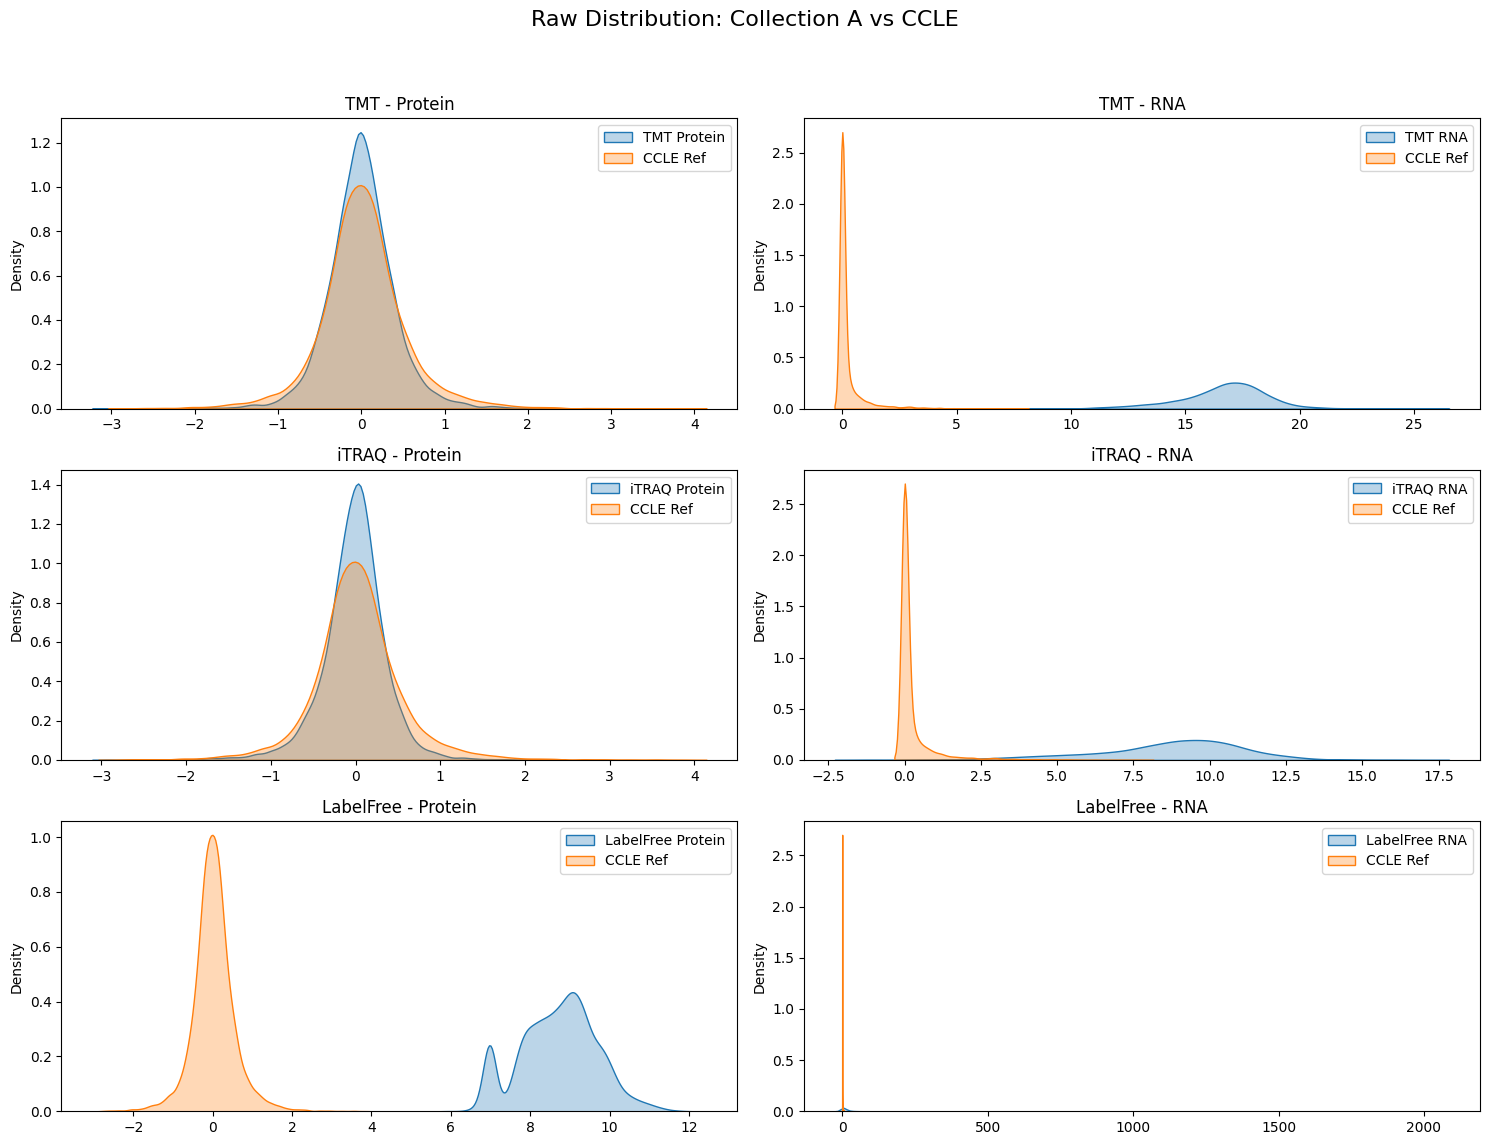

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle("Raw Distribution: Collection A vs CCLE", fontsize=16)

for r, group in enumerate(GROUPS):
    for c, dtype in enumerate(TYPES):
        ax = axes[r][c]
        df_my = data_store[group][dtype]
        df_ref = ccle_prot if dtype == "Protein" else ccle_rna
        
        if df_my is not None:
            # 1. Plot Raw
            sns.kdeplot(df_my.values.flatten()[:10000], ax=ax, label=f"{group} {dtype}", fill=True, alpha=0.3)
            sns.kdeplot(df_ref.values.flatten()[:10000], ax=ax, label="CCLE Ref", fill=True, alpha=0.3)
            ax.set_title(f"{group} - {dtype}")
            ax.legend()
            
            # 2. Stats Print
            print(f"\n>>> STATS: {group} - {dtype}")
            s1 = get_stats(df_my, "My Data")
            s2 = get_stats(df_ref, "CCLE")
            print(pd.concat([s1, s2], axis=1))
            
            # 3. Gene Correlation (Mean Expression)
            common = df_my.columns.intersection(df_ref.columns)
            if len(common) > 10:
                m1 = df_my[common].mean()
                m2 = df_ref[common].mean()
                corr, _ = pearsonr(m1, m2)
                print(f"    Gene Mean Correlation (Pearson): {corr:.4f}")
            
        else:
            ax.text(0.5, 0.5, "No Data", ha='center')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Mixed Logic Comparison

- **Proteomics (TMT, iTRAQ)**: Kept RAW vs CCLE (Raw/Ref).
- **Proteomics (LabelFree)**: **Log2(x+1) + Z-Score** vs **CCLE (Z-Score)**.
- **Transcriptomics (All)**: **Log2(x+1) + Z-Score** vs **CCLE (Z-Score)**.


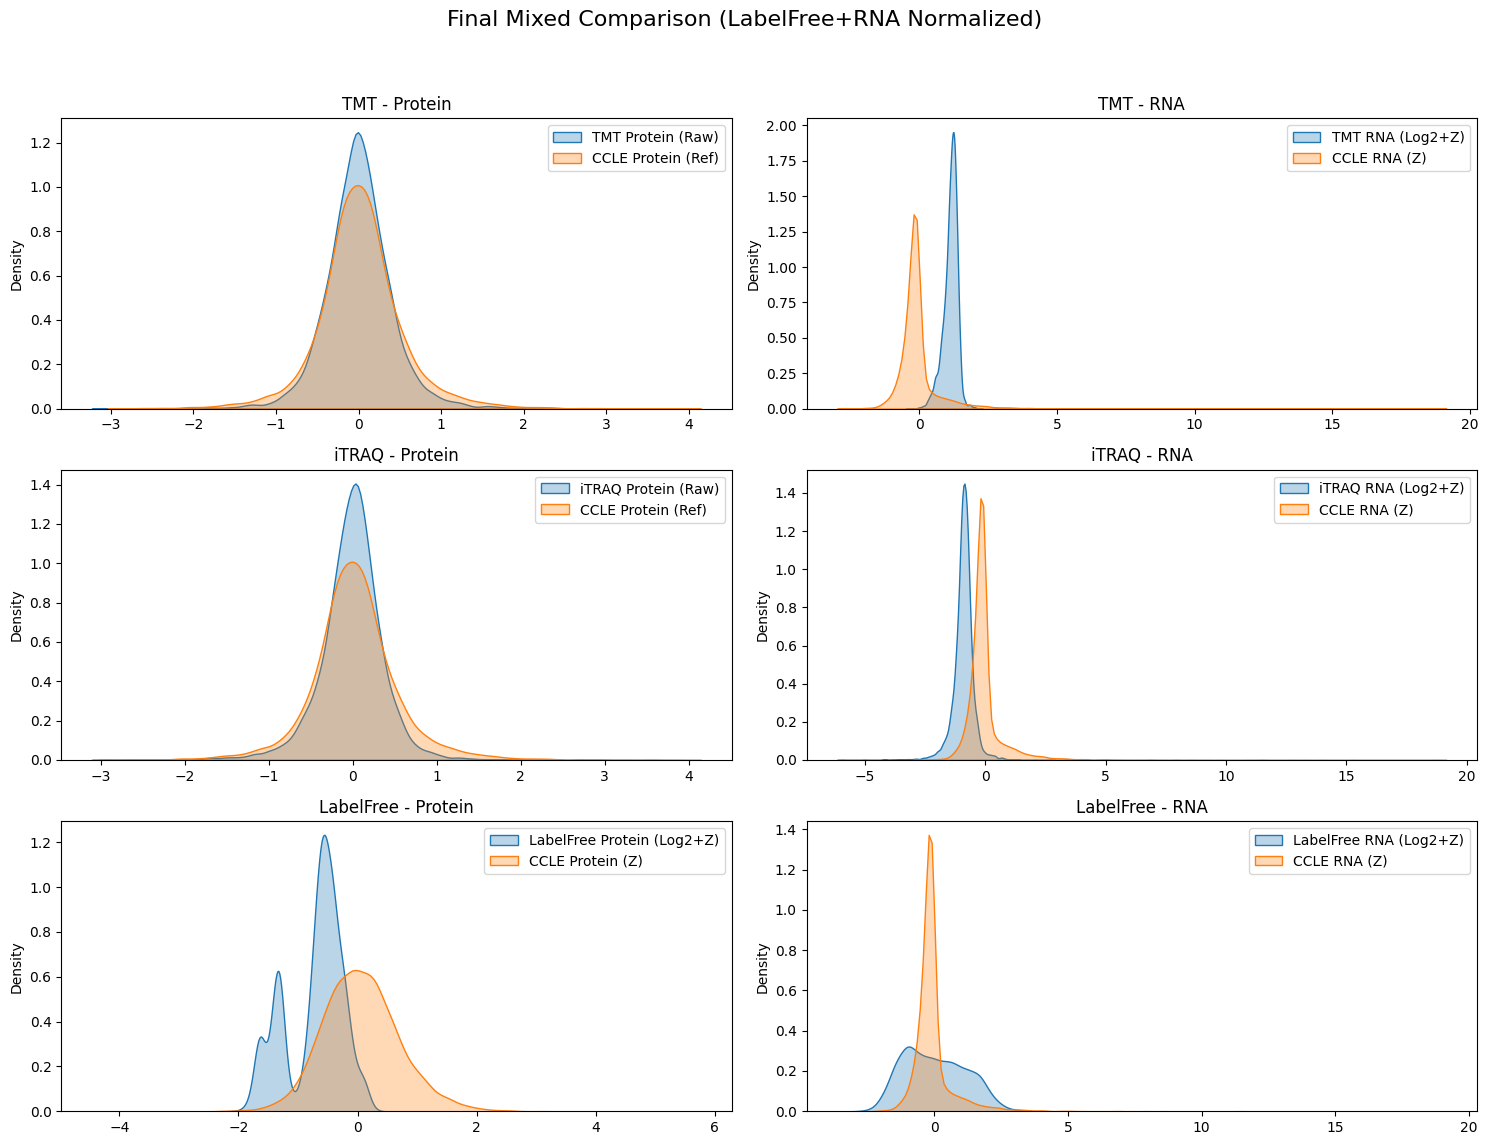

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle("Final Mixed Comparison (LabelFree+RNA Normalized)", fontsize=16)

for r, group in enumerate(GROUPS):
    for c, dtype in enumerate(TYPES):
        ax = axes[r][c]
        df_my = data_store[group][dtype]
        df_ref = ccle_prot if dtype == "Protein" else ccle_rna
        
        if df_my is not None:
            # ==========================================
            # Logic Branching
            # ==========================================
            apply_norm = False
            
            if dtype == "RNA":
                apply_norm = True
            elif dtype == "Protein" and group == "LabelFree":
                apply_norm = True # Special Exception
            
            # ==========================================
            # Normalization Execution
            # ==========================================
            if apply_norm:
                # -----------------
                # My Data: Log2 + Z
                # -----------------
                df_temp = df_my.copy()
                df_temp[df_temp < 0] = 0
                df_log = np.log2(df_temp + 1)
                
                scaler_my = StandardScaler()
                if df_log.shape[0] > 0:
                    scaled_my = scaler_my.fit_transform(df_log)
                    data_my_plot = scaled_my.flatten()
                else:
                    data_my_plot = df_log.values.flatten()

                label_my = f"{group} {dtype} (Log2+Z)"
                
                # -----------------
                # CCLE Ref: Z-Score
                # -----------------
                scaler_ref = StandardScaler()
                if df_ref.shape[0] > 0:
                    scaled_ref = scaler_ref.fit_transform(df_ref)
                    data_ref_plot = scaled_ref.flatten()
                else:
                    data_ref_plot = df_ref.values.flatten()
                    
                label_ref = f"CCLE {dtype} (Z)"
                
            else:
                # -----------------
                # Raw (TMT/iTRAQ Protein)
                # -----------------
                data_my_plot = df_my.values.flatten()
                label_my = f"{group} {dtype} (Raw)"
                
                # Ref Raw
                data_ref_plot = df_ref.values.flatten()
                label_ref = f"CCLE {dtype} (Ref)"

            
            # ---------------------------
            # Plot
            # ---------------------------
            sns.kdeplot(data_my_plot[:10000], ax=ax, label=label_my, fill=True, alpha=0.3)
            sns.kdeplot(data_ref_plot[:10000], ax=ax, label=label_ref, fill=True, alpha=0.3)
            ax.set_title(f"{group} - {dtype}")
            ax.legend()
            
        else:
            ax.text(0.5, 0.5, "No Data", ha='center')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [15]:
print("\n=== Protein Lists in Datasets ===")
print(f"CCLE Proteins ({len(ccle_prot.columns)}):")
# Print sorted list for better readability
print(sorted(list(ccle_prot.columns)))

for group in GROUPS:
    df = data_store[group].get('Protein')
    if df is not None:
        print(f"\n{group} Proteins ({len(df.columns)}):")
        print(sorted(list(df.columns)))
    else:
        print(f"\n{group} Protein data not found.")



=== Protein Lists in Datasets ===
CCLE Proteins (5113):
['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1', 'AAMDC', 'AAMP', 'AAR2', 'AARS', 'AARS2', 'AARSD1', 'AASDHPPT', 'AASS', 'AATF', 'ABCB10', 'ABCB6', 'ABCB7', 'ABCB8', 'ABCC1', 'ABCC4', 'ABCD1', 'ABCD3', 'ABCE1', 'ABCF1', 'ABCF2', 'ABCF3', 'ABHD10', 'ABHD11', 'ABHD12', 'ABHD14B', 'ABHD16A', 'ABI1', 'ABI2', 'ABLIM1', 'ABT1', 'ACAA1', 'ACAA2', 'ACACA', 'ACAD10', 'ACAD8', 'ACAD9', 'ACADM', 'ACADS', 'ACADSB', 'ACADVL', 'ACAP2', 'ACAT1', 'ACAT2', 'ACBD3', 'ACBD5', 'ACBD6', 'ACIN1', 'ACLY', 'ACO1', 'ACO2', 'ACOT13', 'ACOT2', 'ACOT7', 'ACOT8', 'ACOT9', 'ACOX1', 'ACP1', 'ACP2', 'ACP6', 'ACSF2', 'ACSF3', 'ACSL1', 'ACSL3', 'ACSL4', 'ACSL5', 'ACSS2', 'ACTA2', 'ACTB', 'ACTL6A', 'ACTL8', 'ACTN1', 'ACTN4', 'ACTR10', 'ACTR1A', 'ACTR2', 'ACTR3', 'ACTR5', 'ACY1', 'ACYP1', 'ACYP2', 'ADA', 'ADAM10', 'ADAM15', 'ADAM17', 'ADAM9', 'ADAR', 'ADCK3', 'ADCK4', 'ADD1', 'ADD3', 'ADH5', 'ADI1', 'ADIRF', 'ADK', 'ADNP', 'ADO', 'ADPGK', 'ADPRHL2', 'ADRBK1', 'ADRM1', 'ADS

In [16]:


output_dir = "../processed_data/feature_lists"
os.makedirs(output_dir, exist_ok=True)
print(f"\n=== Saving Protein and Feature Lists to {output_dir} ===")

for group in GROUPS:
    # Save Protein List
    df_prot = data_store[group].get('Protein')
    if df_prot is not None:
        prot_list = sorted(list(df_prot.columns))
        prot_file = os.path.join(output_dir, f"{group}_proteins.txt")
        with open(prot_file, 'w') as f:
            for item in prot_list:
                f.write(f"{item}\n")
        print(f"Saved {len(prot_list)} proteins to {prot_file}")
    
    # Save RNA (Feature) List
    df_rna = data_store[group].get('RNA')
    if df_rna is not None:
        # RNA dataframe has columns as genes (features)
        rna_list = sorted(list(df_rna.columns))
        rna_file = os.path.join(output_dir, f"{group}_rna_features.txt")
        with open(rna_file, 'w') as f:
            for item in rna_list:
                f.write(f"{item}\n")
        print(f"Saved {len(rna_list)} RNA features to {rna_file}")

print("Done saving lists.")



=== Saving Protein and Feature Lists to ../processed_data/feature_lists ===
Saved 6885 proteins to ../processed_data/feature_lists\TMT_proteins.txt
Saved 15001 RNA features to ../processed_data/feature_lists\TMT_rna_features.txt
Saved 4994 proteins to ../processed_data/feature_lists\iTRAQ_proteins.txt
Saved 14521 RNA features to ../processed_data/feature_lists\iTRAQ_rna_features.txt
Saved 2563 proteins to ../processed_data/feature_lists\LabelFree_proteins.txt
Saved 14947 RNA features to ../processed_data/feature_lists\LabelFree_rna_features.txt
Done saving lists.


# Feature Intersection Analysis
(Merged from feature_intersection.ipynb)

In [17]:


# Ensure output directory exists
output_dir = "../processed_data/feature_intersections"
os.makedirs(output_dir, exist_ok=True)


In [18]:

# Paths (Relative to notebooks/ directory)
TRANSCRIPTOMICS_PATH = "../processed_data/transcriptomics_filtered.joblib"
FEAT_LIST_DIR = "../processed_data/feature_lists"

TMT_PATH = os.path.join(FEAT_LIST_DIR, "TMT_rna_features.txt")
ITRAQ_PATH = os.path.join(FEAT_LIST_DIR, "iTRAQ_rna_features.txt")
LF_PATH = os.path.join(FEAT_LIST_DIR, "LabelFree_rna_features.txt")

# Load Transcriptomics Data
print(f"Loading {TRANSCRIPTOMICS_PATH}...")
try:
    data = joblib.load(TRANSCRIPTOMICS_PATH)
    if isinstance(data, pd.DataFrame):
        transcriptomics_genes = set(data.columns)
        print(f"Loaded DataFrame with {len(transcriptomics_genes)} features.")
    elif isinstance(data, (list, set, np.ndarray)):
        transcriptomics_genes = set(data)
        print(f"Loaded list/set with {len(transcriptomics_genes)} features.")
    else:
        print(f"Unknown type: {type(data)}")
        transcriptomics_genes = set()
except Exception as e:
    print(f"Error loading transcriptomics: {e}")
    transcriptomics_genes = set()

# Load Other Feature Lists
def load_feature_list(path):
    if not os.path.exists(path):
        print(f"Warning: {path} not found.")
        return set()
    with open(path, 'r') as f:
        # Assuming one gene per line or comma separated? 
        # Usually these .txt files are one per line based on previous context.
        content = f.read().strip().splitlines()
    return set(x.strip() for x in content if x.strip())

tmt_genes = load_feature_list(TMT_PATH)
itraq_genes = load_feature_list(ITRAQ_PATH)
lf_genes = load_feature_list(LF_PATH)

print(f"TMT Genes: {len(tmt_genes)}")
print(f"iTRAQ Genes: {len(itraq_genes)}")
print(f"LabelFree Genes: {len(lf_genes)}")


Loading ../processed_data/transcriptomics_filtered.joblib...
Loaded DataFrame with 22614 features.
TMT Genes: 15001
iTRAQ Genes: 14521
LabelFree Genes: 14947


In [19]:

# Calculate Intersections

# 1. Transcriptomics AND TMT
common_tmt = transcriptomics_genes.intersection(tmt_genes)
print(f"Transcriptomics & TMT: {len(common_tmt)}")

# 2. Transcriptomics AND iTRAQ
common_itraq = transcriptomics_genes.intersection(itraq_genes)
print(f"Transcriptomics & iTRAQ: {len(common_itraq)}")

# 3. Transcriptomics AND LabelFree
common_lf = transcriptomics_genes.intersection(lf_genes)
print(f"Transcriptomics & LabelFree: {len(common_lf)}")

# 4. Common to ALL 4
common_all = transcriptomics_genes.intersection(tmt_genes).intersection(itraq_genes).intersection(lf_genes)
print(f"Common to ALL 4: {len(common_all)}")


Transcriptomics & TMT: 12833
Transcriptomics & iTRAQ: 12380
Transcriptomics & LabelFree: 12673
Common to ALL 4: 11822


In [20]:

def save_list(gene_set, filename):
    filepath = os.path.join(output_dir, filename)
    with open(filepath, 'w') as f:
        for gene in sorted(list(gene_set)):
            f.write(f"{gene}\n")
    print(f"Saved {len(gene_set)} genes to {filepath}")

save_list(common_tmt, "transcriptomics_and_TMT.txt")
save_list(common_itraq, "transcriptomics_and_iTRAQ.txt")
save_list(common_lf, "transcriptomics_and_LabelFree.txt")
save_list(common_all, "common_all_datasets.txt")


Saved 12833 genes to ../processed_data/feature_intersections\transcriptomics_and_TMT.txt
Saved 12380 genes to ../processed_data/feature_intersections\transcriptomics_and_iTRAQ.txt
Saved 12673 genes to ../processed_data/feature_intersections\transcriptomics_and_LabelFree.txt
Saved 11822 genes to ../processed_data/feature_intersections\common_all_datasets.txt


In [21]:

try:
    import matplotlib.pyplot as plt
    from matplotlib_venn import venn3
    
    # We can't easily do a 4-way venn with standard lib, usually 3 is max for readable.
    # Let's do Transcriptomics vs TMT vs iTRAQ
    
    plt.figure(figsize=(10, 10))
    venn3([transcriptomics_genes, tmt_genes, itraq_genes], ('Transcriptomics', 'TMT', 'iTRAQ'))
    plt.title("Overlap: Transcriptomics vs TMT vs iTRAQ")
    plt.show()
    
except ImportError:
    print("matplotlib-venn not installed, skipping visualization.")
except Exception as e:
    print(f"Error in visualization: {e}")


matplotlib-venn not installed, skipping visualization.


In [22]:

# --- SAVE TRANSFORMED VALIDATION DATA (End of Notebook) ---


print("Processing and saving validation datasets...")

if 'data_store' in locals():
    for group in GROUPS:
        for dtype in TYPES:
            if group in data_store and dtype in data_store[group]:
                original_df = data_store[group][dtype]
                
                if original_df is not None:
                    # Create a copy to avoid modifying the original analysis data
                    df_to_save = original_df.copy()
                    
                    # Apply transformations for RNA (Transcriptomics)
                    if dtype == "RNA":
                        print(f"Applying Log2 and Z-score to {group} {dtype}...")
                        
                        # 1. Log2 Transform (log2(x + 1) to handle zeros)
                        # Check if data is already logged? (Small max value)
                        # If max > 100, assume raw and log.
                        if df_to_save.max().max() > 100:
                             # Handle negatives if any (though counts shouldn't be negative)
                             # If min < 0, shift to 0
                             min_val = df_to_save.min().min()
                             if min_val < 0:
                                 df_to_save = df_to_save - min_val
                             
                             df_to_save = np.log2(df_to_save + 1)
                        else:
                            print(f"  > Skipping Log2 for {group} {dtype} (Max value {df_to_save.max().max():.2f} <= 100, assuming already logged)")

                        # 2. Z-score Normalize (Feature/Gene-wise)
                        # Apply zscore to each column (gene)
                        # Use nan_policy='omit' to avoid NaN propagation
                        df_to_save = df_to_save.apply(zscore, axis=0, nan_policy='omit')
                    
                    # Construct filename
                    type_suffix = "proteomics" if dtype == "Protein" else "transcriptomics"
                    filename = f"{group}_{type_suffix}.joblib"
                    out_path = os.path.join(val_dir, filename)
                    
                    joblib.dump(df_to_save, out_path)
                    print(f"Saved {out_path} (Shape: {df_to_save.shape})")
                else:
                    print(f"Skipping {group} {dtype} (Data is None)")
else:
    print("Error: data_store not found.")
# ----------------------------------------------------------


Processing and saving validation datasets...
Saved ../val_data\TMT_proteomics.joblib (Shape: (1924, 6885))
Applying Log2 and Z-score to TMT RNA...
Saved ../val_data\TMT_transcriptomics.joblib (Shape: (1924, 15001))
Saved ../val_data\iTRAQ_proteomics.joblib (Shape: (276, 4994))
Applying Log2 and Z-score to iTRAQ RNA...
  > Skipping Log2 for iTRAQ RNA (Max value 29.21 <= 100, assuming already logged)
Saved ../val_data\iTRAQ_transcriptomics.joblib (Shape: (276, 14521))
Saved ../val_data\LabelFree_proteomics.joblib (Shape: (360, 2563))
Applying Log2 and Z-score to LabelFree RNA...
Saved ../val_data\LabelFree_transcriptomics.joblib (Shape: (360, 14947))
